# 08 | Gráficos

Gráficos da taxa de homicídios e dos registros RAND por estado e ano, e da relação entre os dois. As figuras são salvas em `reports/figures/`.

**Como usar:** execute antes 01 → 07. Depois rode os três blocos na ordem.

## Bloco 1: Taxa de homicídios

O primeiro gráfico mostra a taxa de cada estado em cada ano. O segundo mostra a trajetória de todos os estados juntos.

Salvo: reports/figures/homicidios_estado_ano.png
Salvo: reports/figures/homicidios_linhas.png


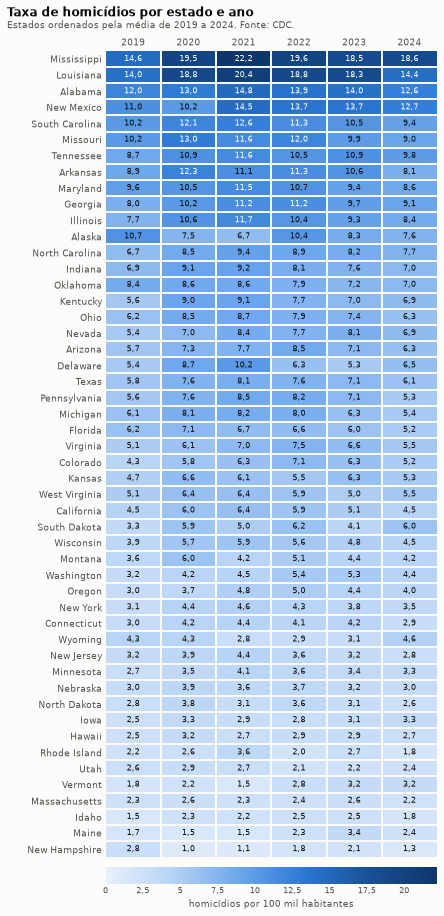

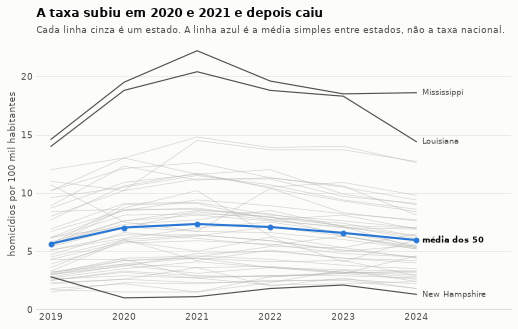

Estados com taxa maior em 2024 do que em 2019: 32 | menor: 16 | igual: 2


,mean,min,max
year,,,
2019,5.65,1.5,14.6
2020,7.03,1.0,19.5
2021,7.34,1.1,22.2
2022,7.08,1.8,19.6
2023,6.57,2.1,18.5
2024,5.96,1.3,18.6


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import importlib
import src.association_plots as graficos
importlib.reload(graficos)

painel = pd.read_csv(ROOT / "data/processed/us_gun_policy_panel_2019_2024.csv")
pasta = ROOT / "reports/figures"
pasta.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 70

def salvar(fig, nome):
    fig.savefig(pasta / nome, dpi=150, facecolor=fig.get_facecolor())
    print("Salvo:", (pasta / nome).relative_to(ROOT))

salvar(graficos.mapa_homicidios(painel), "homicidios_estado_ano.png")
salvar(graficos.linhas_homicidios(painel), "homicidios_linhas.png")
plt.show()

comeco = painel[painel["year"] == 2019].set_index("state")["homicide_rate"]
final = painel[painel["year"] == 2024].set_index("state")["homicide_rate"]
print("Estados com taxa maior em 2024 do que em 2019:", (final > comeco).sum(), "| menor:", (final < comeco).sum(), "| igual:", (final == comeco).sum())
display(painel.groupby("year")["homicide_rate"].agg(["mean", "min", "max"]).round(2))

A diferença entre estados é muito maior do que a mudança de um ano para outro. O Mississippi fica perto de 20 por 100 mil e New Hampshire perto de 1 ou 2. Quase todos os estados subiram em 2020 e 2021 e caíram depois, com leis muito diferentes entre si. Esse movimento geral é o que o modelo desconta com o efeito de ano.

## Bloco 2: Registros RAND

Para cada estado, a contagem de registros restritivos e permissivos no fim de 2019 e no fim de 2024.

Salvo: reports/figures/regras_estado.png


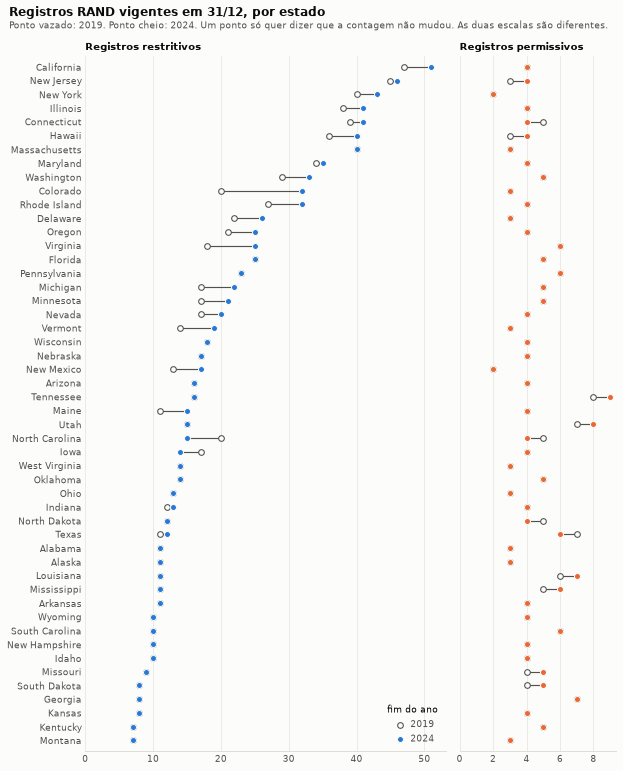

Estados sem nenhuma mudança nos restritivos: 27
Estados sem nenhuma mudança nos permissivos: 38


,restrictive_records,permissive_records
state,,
North Carolina,-5,-1
Iowa,-3,0
Rhode Island,5,0
Virginia,7,0
Colorado,12,0


,restrictive_records,permissive_records
year,,
2019,18.60,4.32
2020,19.00,4.34
2021,19.18,4.28
2022,19.50,4.30
2023,19.76,4.28
2024,20.06,4.40


In [2]:
salvar(graficos.regras_por_estado(painel), "regras_estado.png")
plt.show()

inicio = painel[painel["year"] == 2019].set_index("state")
fim = painel[painel["year"] == 2024].set_index("state")
mudanca = (fim[["restrictive_records", "permissive_records"]] - inicio[["restrictive_records", "permissive_records"]])
print("Estados sem nenhuma mudança nos restritivos:", (mudanca["restrictive_records"] == 0).sum())
print("Estados sem nenhuma mudança nos permissivos:", (mudanca["permissive_records"] == 0).sum())
display(mudanca.sort_values("restrictive_records").iloc[[0, 1, -3, -2, -1]])
display(painel.groupby("year")[["restrictive_records", "permissive_records"]].mean().round(2))

A contagem de restritivos vai de 7 (Montana, Kentucky) a 51 (Califórnia), mas quase não se mexe dentro de cada estado. O Colorado é a exceção, com 12 registros a mais. Na contagem de permissivos, a maior mudança em qualquer estado foi de um registro.

## Bloco 3: Relação entre regras e homicídios

À esquerda comparamos estados entre si. À direita comparamos cada estado com ele mesmo, que é o que o modelo do 06 faz. O último gráfico mostra os coeficientes do 06 e dos testes do 07.

Salvo: reports/figures/relacao_regras_homicidios.png
Salvo: reports/figures/coeficientes.png


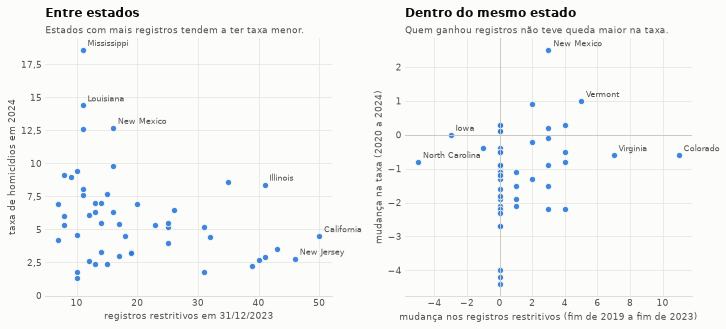

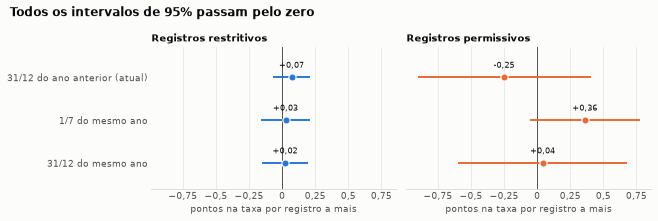

Correlação entre estados (registros no fim de 2023 x taxa de 2024): -0.31
Correlação das mudanças dentro do estado: 0.22


,count,mean
d_regras,,
ganhou registros,20,-0.63
não mudou,27,-1.49
perdeu registros,3,-0.40


Correlação entre renda de 2023 e taxa de 2024: -0.56
Correlação entre renda de 2023 e registros restritivos: 0.66


In [3]:
fig, nivel, variacao = graficos.relacao(
    painel,
    rotulos_nivel=["Mississippi", "Louisiana", "New Mexico", "California", "New Jersey", "Illinois"],
    rotulos_mudanca=["Colorado", "North Carolina", "Virginia", "Iowa", "New Mexico", "Vermont"])
salvar(fig, "relacao_regras_homicidios.png")

sensibilidade = pd.read_csv(ROOT / "reports/results/cutoff_sensitivity.csv")
salvar(graficos.coeficientes(sensibilidade), "coeficientes.png")
plt.show()

print("Correlação entre estados (registros no fim de 2023 x taxa de 2024):",
      round(nivel["restrictive_records"].corr(nivel["homicide_rate"]), 2))
print("Correlação das mudanças dentro do estado:", round(variacao["d_regras"].corr(variacao["d_taxa"]), 2))
grupo = variacao["d_regras"].apply(lambda x: "ganhou registros" if x > 0 else ("não mudou" if x == 0 else "perdeu registros"))
display(variacao.groupby(grupo)["d_taxa"].agg(["count", "mean"]).round(2))
renda = painel[painel["year"] == 2023].set_index("state")["income_per_capita"]
print("Correlação entre renda de 2023 e taxa de 2024:", round(renda.corr(nivel["homicide_rate"]), 2))
print("Correlação entre renda de 2023 e registros restritivos:", round(renda.corr(nivel["restrictive_records"]), 2))

Entre estados existe uma relação: quem tem mais registros restritivos tende a ter taxa menor. Só que esses estados também são mais ricos e diferentes em várias outras coisas, então essa comparação sozinha não diz nada sobre as leis.

Quando olhamos a mudança dentro de cada estado, essa relação não aparece. Os 20 estados que ganharam registros restritivos tiveram queda média de 0,63 ponto na taxa entre 2020 e 2024. Os 27 que não mudaram nada tiveram queda de 1,49. Isso não quer dizer que mais regras atrapalharam: os estados que não mudaram já tinham taxa mais alta em 2020, subiram mais na pandemia e depois caíram mais. O Colorado ganhou 11 registros e a taxa dele caiu 0,6, igual à da Virgínia, que ganhou 7.

Por isso os coeficientes do modelo ficam perto de zero, com intervalos largos.